# Advanced EDA — VLC Simulation Dataset

Dataset: `part-00000.parquet`

## 1. Setup

In [2]:
%pip install pyarrow plotly missingno scikit-learn --upgrade

Note: you may need to restart the kernel to use updated packages.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import missingno as msno
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from scipy import stats
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", 200)

## 2. Load Data

In [33]:
path = '../backend/datasets/run_1785559836/train/part-00000.parquet'
df = pd.read_parquet(path)
df.shape

(1000, 91)

## 3. Structural Overview

In [34]:
df.head()

,env_room_width,env_room_length,env_room_height,env_wall_reflectivity,env_floor_reflectivity,env_ceiling_reflectivity,env_num_leds,env_rx_x,env_rx_y,env_rx_z,env_rx_fov_deg,env_num_obstacles,env_mobility_type,env_rx_speed_ms,env_simulation_time,env_frame_index,phys_avg_snr_db,phys_min_snr_db,phys_max_snr_db,phys_avg_los_gain,phys_avg_nlos_gain,phys_avg_received_power_w,phys_avg_noise_variance,phys_num_los_links,phys_total_received_power_w,comm_sum_rate_mbps,comm_spectral_eff,comm_avg_ber,comm_max_ber,comm_jains_fairness,comm_fft_size,comm_bandwidth_mhz,comm_num_active_subcarriers,loc_est_x,loc_est_y,loc_est_z,loc_error_3d_m,loc_confidence,loc_status,alloc_sum_rate_mbps,alloc_qos_status,alloc_num_subcarriers_used,alloc_avg_modulation_order,power_total_budget_w,power_loc_reserved_w,power_comm_available_w,power_nominal_rate_mbps,power_feasible_rate_mbps,power_preeq_mode,power_mode,opt_iterations,opt_converged,opt_sum_rate_mbps,opt_loc_error_m,opt_total_power_w,opt_feasible,label_power_vector_w,label_loc_power_per_led_w,label_gt_x,label_gt_y,label_gt_z,label_est_x,label_est_y,label_est_z,label_disc_x,label_disc_y,label_disc_z,label_disc_3d_m,label_disc_2d_m,label_disc_bearing_deg,label_disc_elevation_deg,label_avg_modulation_order,label_sum_modulation_bits,label_rho_active_fraction,label_qos_feasible,label_joint_sum_rate_mbps,label_joint_converged,label_joint_feasible,meta_sample_id,meta_simulation_seed,meta_scenario_type,meta_pipeline_mode,meta_generator_version,meta_physics_version,meta_optimizer_version,meta_timestamp,meta_is_valid,meta_rejection_reason,meta_runtime_ms,meta_split,meta_sample_index
0,3.000000,3.606284,3.010382,0.733554,0.198907,0.700496,1,0.462131,2.127654,0.898339,68.469930,1,,0.194274,0.05,1,26.217361,26.217361,26.217361,0.000000,3.749351e-07,0.000002,2.680590e-15,0,0.000002,0.00000,0.000000,0.504545,0.504545,0.000000,-1,37.786892,0,1.500000,1.803142e+00,0.85,1.088493,0.0,INSUFFICIENT_GEOMETRY,0.00000,INFEASIBLE_QOS,0,NaN,40.0,4.0,12.0,0.00000,0.00000,REGULARIZED,WATER_FILLING,1,False,0.00000,2.177800,16.0,False,16.000000,4.000000,0.462131,2.127654,0.898339,1.500000,1.803142e+00,0.85,1.037869,-0.324512,-0.048339,1.088493,1.087419,-17.362991,-2.545286,NaN,0,0.000000,False,0.00000,False,False,ds-0280df02-00000004,42000130,meeting_room,optimize,1.0.0,2.1,1.3,2026-08-01T04:50:40.742498+00:00,True,,411.8179,train,4
1,3.500000,22.843400,3.944252,0.815799,0.082378,0.710499,7,2.352267,12.454117,1.124571,56.039950,0,,0.000000,0.05,1,1.694493,-47.140118,75.698074,0.000009,1.300531e-08,0.000140,3.158517e-15,0,0.000980,32.65625,0.820871,0.423214,0.550000,0.186023,-1,39.782421,0,1.571324,5.422813e-08,0.85,12.481598,0.0,LOW_CONFIDENCE,32.65625,INFEASIBLE_QOS,53,245.132075,40.0,0.0,42.0,32.65625,32.65625,REGULARIZED,WATER_FILLING,1,False,32.65625,10.405255,42.0,False,6.000000,0.000000,2.352267,12.454117,1.124571,1.571324,5.422813e-08,0.85,-0.780943,-12.454117,-0.274571,12.481598,12.478577,-93.588067,-1.260499,245.132075,418,0.118304,False,32.65625,False,False,ds-0280df12-00000014,42000146,corridor,optimize,1.0.0,2.1,1.3,2026-08-01T04:50:52.581375+00:00,True,,526.5815,train,20
2,4.352808,4.770309,3.529676,0.880859,0.309218,0.751830,4,3.657997,2.429307,0.819501,75.582903,2,,0.883178,0.05,1,69.133753,63.970174,76.612748,0.000016,1.068607e-06,0.000434,4.176250e-15,0,0.001737,55.78125,2.066467,0.124306,0.497222,0.519225,-1,26.993535,0,3.630510,2.421011e+00,0.85,0.041887,0.0,LOW_CONFIDENCE,55.78125,FEASIBLE,110,137.309091,40.0,4.0,44.0,55.78125,55.78125,REGULARIZED,WATER_FILLING,1,False,55.78125,4.391181,48.0,False,12.000000,1.000000,3.657997,2.429307,0.819501,3.630510,2.421011e+00,0.85,-0.027487,-0.008296,0.030499,0.041887,0.028711,-163.204885,46.729760,137.309091,714,0.214844,True,55.78125,False,False,ds-0280df1b-0000001d,42000155,meeting_room,optimize,1.0.0,2.1,1.3,2026-08-01T04:51:02.296543+00:00,True,,499.1932,train,29
3,5.022252,6.051574,4.905205,0.854045,0.111664,0.560508,4,4.051568,3.006905,0.751854,68.821817,4,,0.000000,0

In [35]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 91 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   env_room_width               1000 non-null   float64
 1   env_room_length              1000 non-null   float64
 2   env_room_height              1000 non-null   float64
 3   env_wall_reflectivity        1000 non-null   float64
 4   env_floor_reflectivity       1000 non-null   float64
 5   env_ceiling_reflectivity     1000 non-null   float64
 6   env_num_leds                 1000 non-null   int64  
 7   env_rx_x                     1000 non-null   float64
 8   env_rx_y                     1000 non-null   float64
 9   env_rx_z                     1000 non-null   float64
 10  env_rx_fov_deg               1000 non-null   float64
 11  env_num_obstacles            1000 non-null   int64  
 12  env_mobility_type            1000 non-null   str    
 13  env_rx_speed_ms              1

In [36]:
prefixes = sorted(set(c.split("_")[0] for c in df.columns))
groups = {p: [c for c in df.columns if c.startswith(p + "_")] for p in prefixes}
for p, cols in groups.items():
    print(p, len(cols))


alloc 4
comm 8
env 16
label 22
loc 6
meta 13
opt 6
phys 9
power 7


In [37]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
env_room_width,1000.0,NaN,NaN,NaN,6.144884,2.655346,3.0,3.640199,5.681418,7.646226,14.902638
env_room_length,1000.0,NaN,NaN,NaN,8.226003,5.581371,3.0,4.785577,6.758995,9.323289,29.939885
env_room_height,1000.0,NaN,NaN,NaN,3.729389,0.662591,2.508042,3.178552,3.74523,4.232175,5.380009
env_wall_reflectivity,1000.0,NaN,NaN,NaN,0.789472,0.086316,0.506869,0.730123,0.803331,0.859723,0.943959
env_floor_reflectivity,1000.0,NaN,NaN,NaN,0.152154,0.055521,0.050914,0.109858,0.146601,0.18716,0.361602
...,...,...,...,...,...,...,...,...,...,...,...
meta_is_valid,1000,1,True,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meta_rejection_reason,1000,1,,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meta_runtime_ms,1000.0,NaN,NaN,NaN,825.090521,684.292831,124.4162,331.117925,577.4337,1163.459325,3391.1082
meta_split,1000,1,train,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Missing Values

In [38]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_df = missing_df[missing_df["missing"] > 0].sort_values("pct", ascending=False)
missing_df

,missing,pct
alloc_avg_modulation_order,53,5.3
label_avg_modulation_order,53,5.3


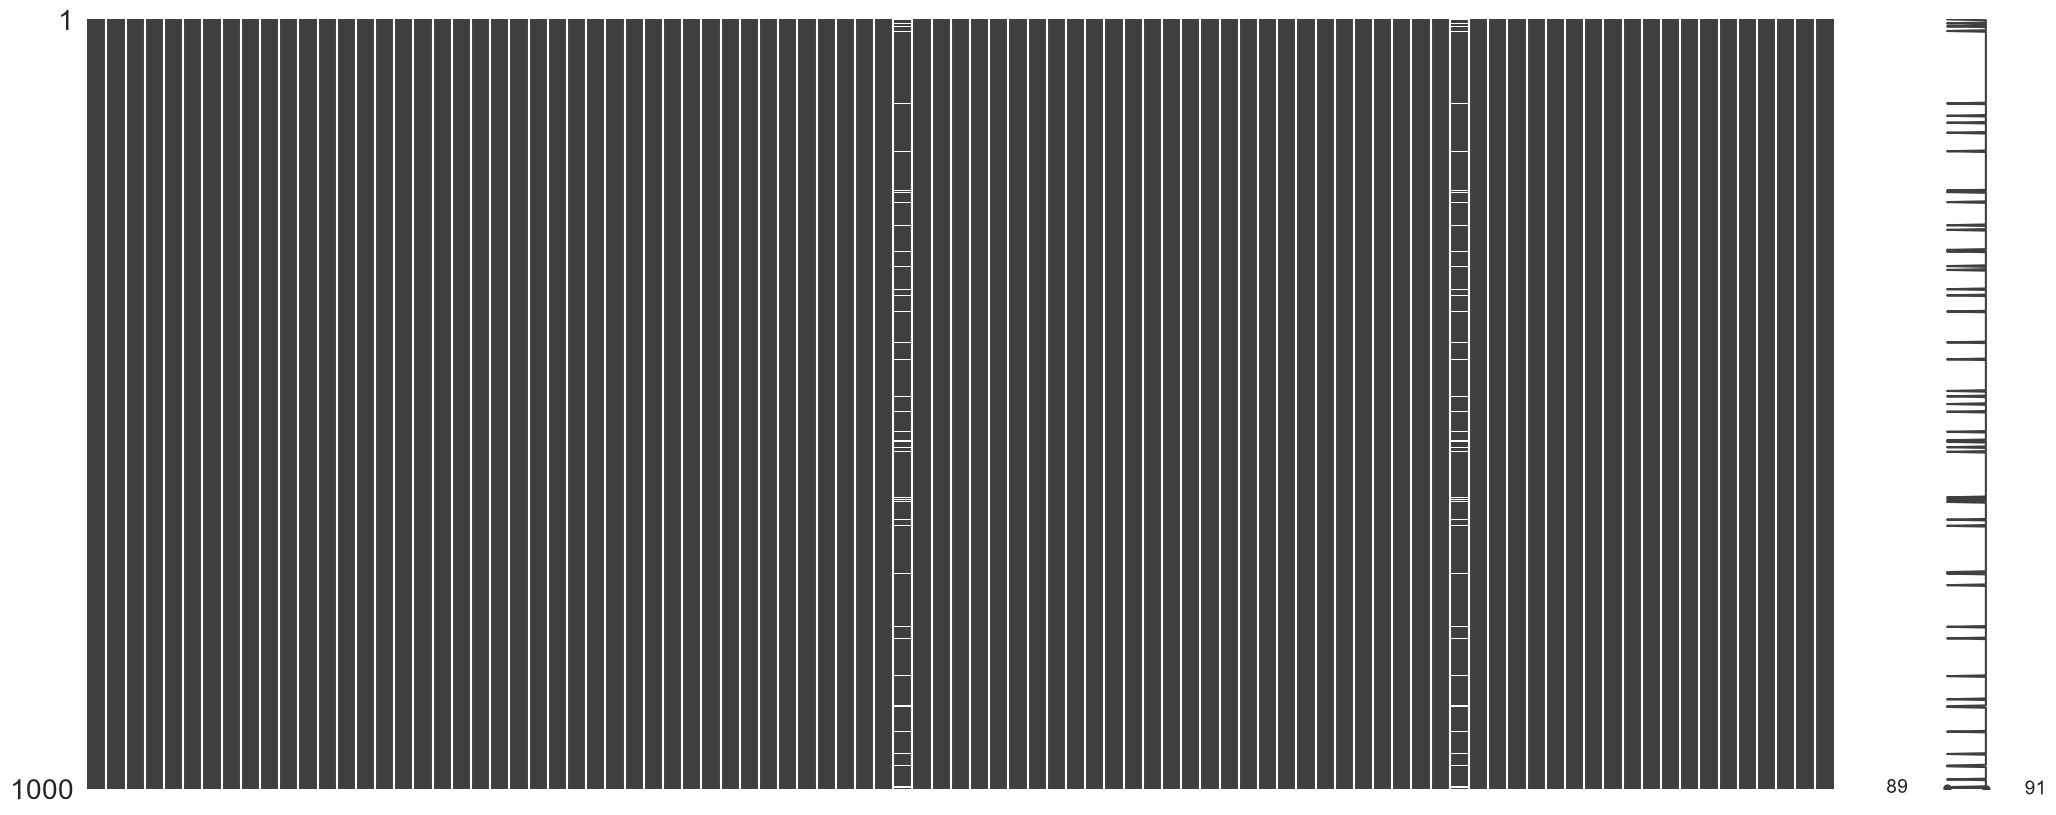

In [39]:
msno.matrix(df)
plt.show()

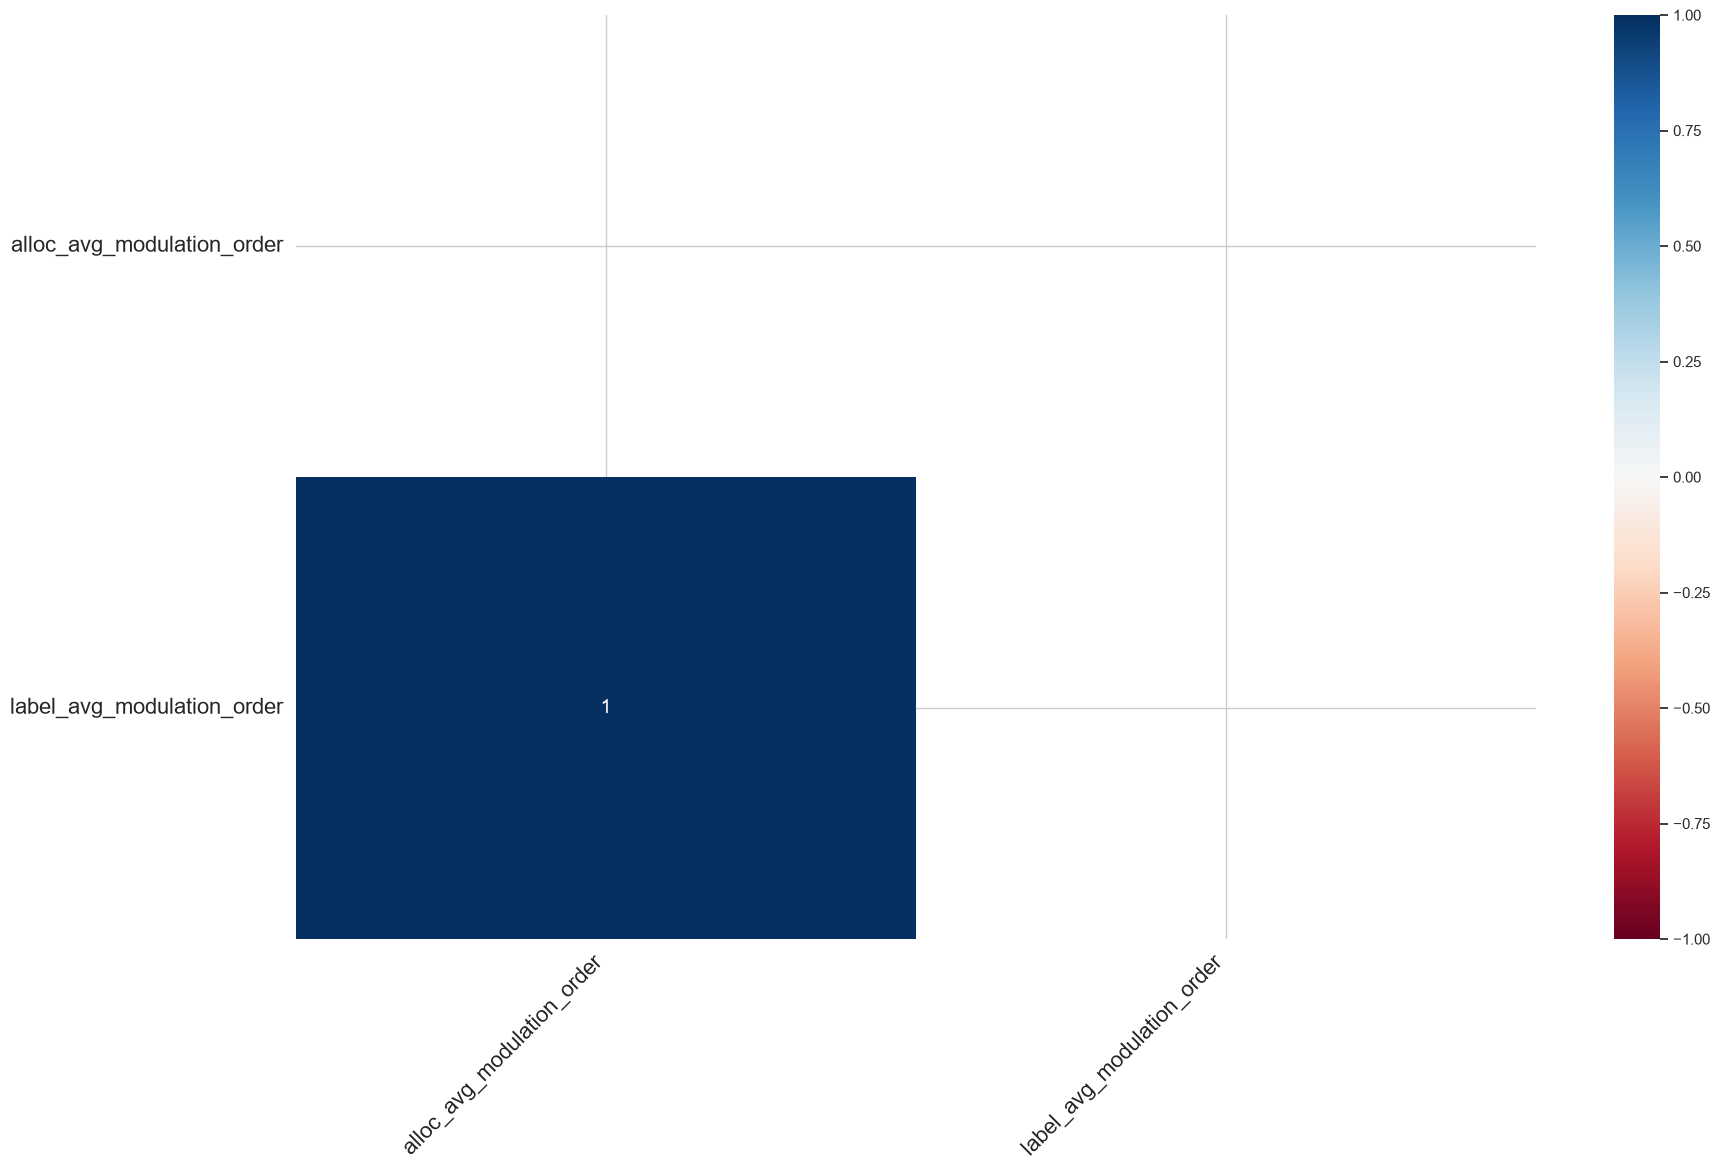

In [40]:
msno.heatmap(df)
plt.show()

## 5. Duplicates & Constant Columns

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
nunique = df.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
constant_cols

['env_mobility_type',
 'env_simulation_time',
 'env_frame_index',
 'phys_num_los_links',
 'comm_fft_size',
 'comm_num_active_subcarriers',
 'loc_est_z',
 'loc_confidence',
 'power_total_budget_w',
 'power_preeq_mode',
 'power_mode',
 'opt_iterations',
 'opt_converged',
 'opt_feasible',
 'label_est_z',
 'label_joint_converged',
 'label_joint_feasible',
 'meta_pipeline_mode',
 'meta_generator_version',
 'meta_physics_version',
 'meta_optimizer_version',
 'meta_is_valid',
 'meta_rejection_reason',
 'meta_split']

In [43]:
id_like_cols = [c for c in df.columns if df[c].nunique() == len(df)]
id_like_cols

['env_room_height',
 'env_wall_reflectivity',
 'env_floor_reflectivity',
 'env_ceiling_reflectivity',
 'env_rx_x',
 'env_rx_y',
 'env_rx_z',
 'env_rx_fov_deg',
 'phys_avg_snr_db',
 'phys_max_snr_db',
 'phys_avg_received_power_w',
 'phys_avg_noise_variance',
 'phys_total_received_power_w',
 'comm_bandwidth_mhz',
 'loc_error_3d_m',
 'opt_loc_error_m',
 'label_gt_x',
 'label_gt_y',
 'label_gt_z',
 'label_disc_x',
 'label_disc_y',
 'label_disc_z',
 'label_disc_3d_m',
 'label_disc_2d_m',
 'label_disc_bearing_deg',
 'label_disc_elevation_deg',
 'meta_sample_id',
 'meta_simulation_seed',
 'meta_timestamp',
 'meta_runtime_ms',
 'meta_sample_index']

## 6. Categorical Columns

In [44]:
cat_cols = df.select_dtypes(include=["object", "string", "bool"]).columns.tolist()
cat_cols = [c for c in cat_cols if c not in constant_cols + id_like_cols]
cat_cols

['loc_status', 'alloc_qos_status', 'label_qos_feasible', 'meta_scenario_type']

In [45]:
for c in cat_cols:
    print(c)
    print(df[c].value_counts(dropna=False))
    print()

loc_status
loc_status
INSUFFICIENT_GEOMETRY    502
LOW_CONFIDENCE           380
SOLVER_FAILED            118
Name: count, dtype: int64

alloc_qos_status
alloc_qos_status
INFEASIBLE_QOS    598
FEASIBLE          402
Name: count, dtype: int64

label_qos_feasible
label_qos_feasible
False    598
True     402
Name: count, dtype: int64

meta_scenario_type
meta_scenario_type
lab             266
meeting_room    250
open_office     198
corridor        160
lobby           126
Name: count, dtype: int64



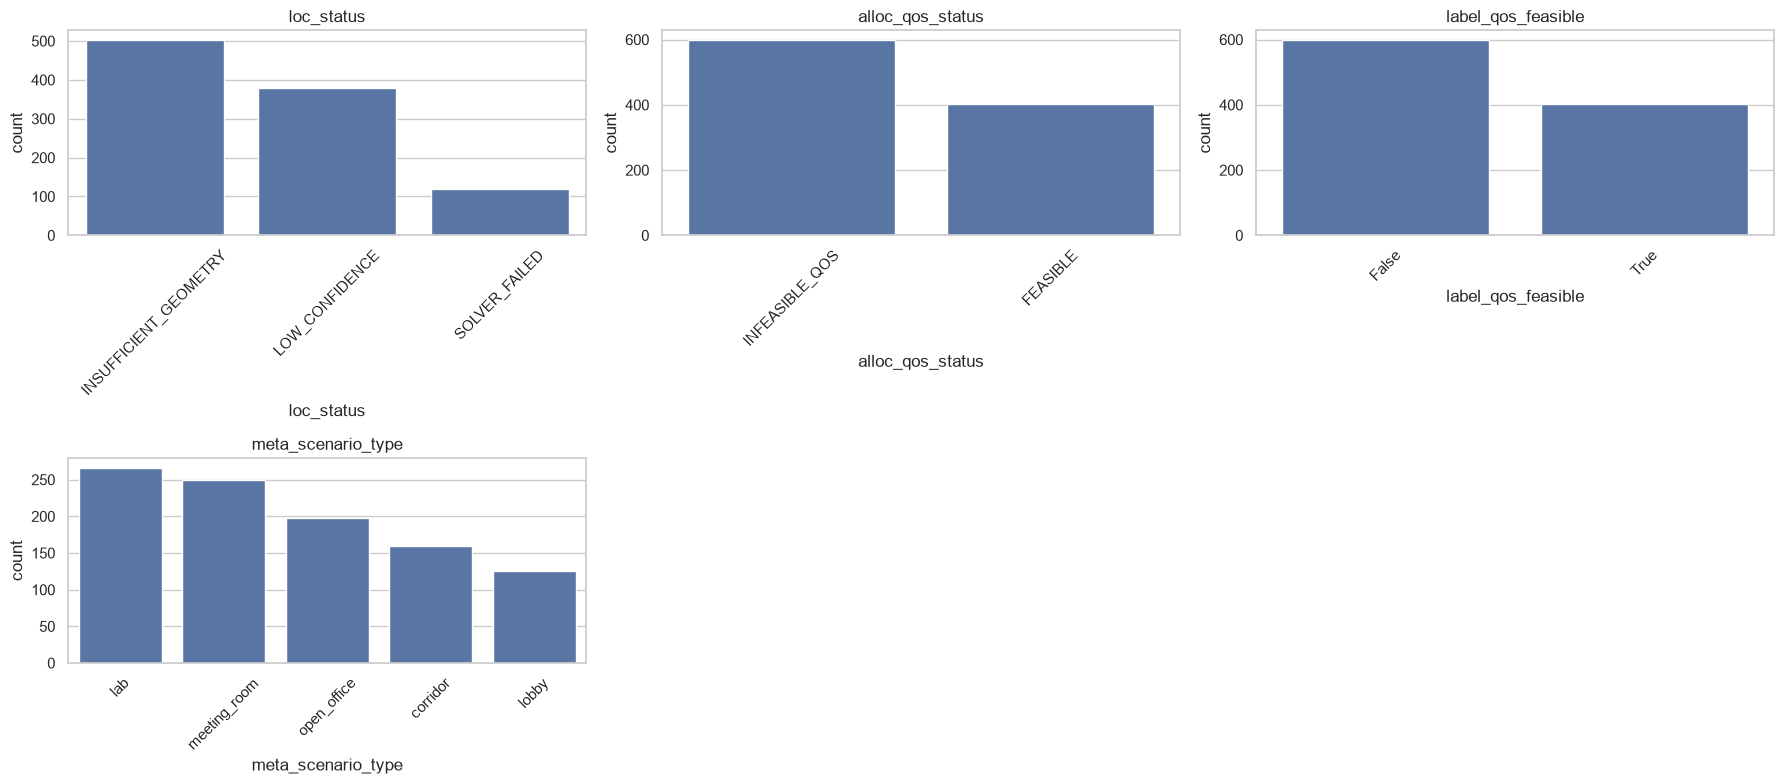

In [46]:
n = len(cat_cols)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(18, 4 * ((n + 2) // 3)))
axes = axes.flatten()
for i, c in enumerate(cat_cols):
    order = df[c].astype(str).value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=axes[i])
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].set_title(c)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

## 7. Numerical Columns — Distributions

In [47]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in constant_cols + id_like_cols]
len(num_cols)

32

In [48]:
skew_kurt = pd.DataFrame({
    "skew": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurtosis()
}).sort_values("skew", ascending=False)
skew_kurt

,skew,kurtosis
phys_avg_los_gain,4.416836,35.772179
phys_avg_nlos_gain,2.807918,11.141724
loc_est_y,2.263654,6.761036
label_est_y,2.263654,6.761036
env_room_length,2.106121,4.289867
comm_spectral_eff,2.083185,5.682975
label_est_x,1.490728,4.772205
loc_est_x,1.490728,4.772205
label_sum_modulation_bits,1.365918,1.618462
power_feasible_rate_mbps,1.365918,1.618462


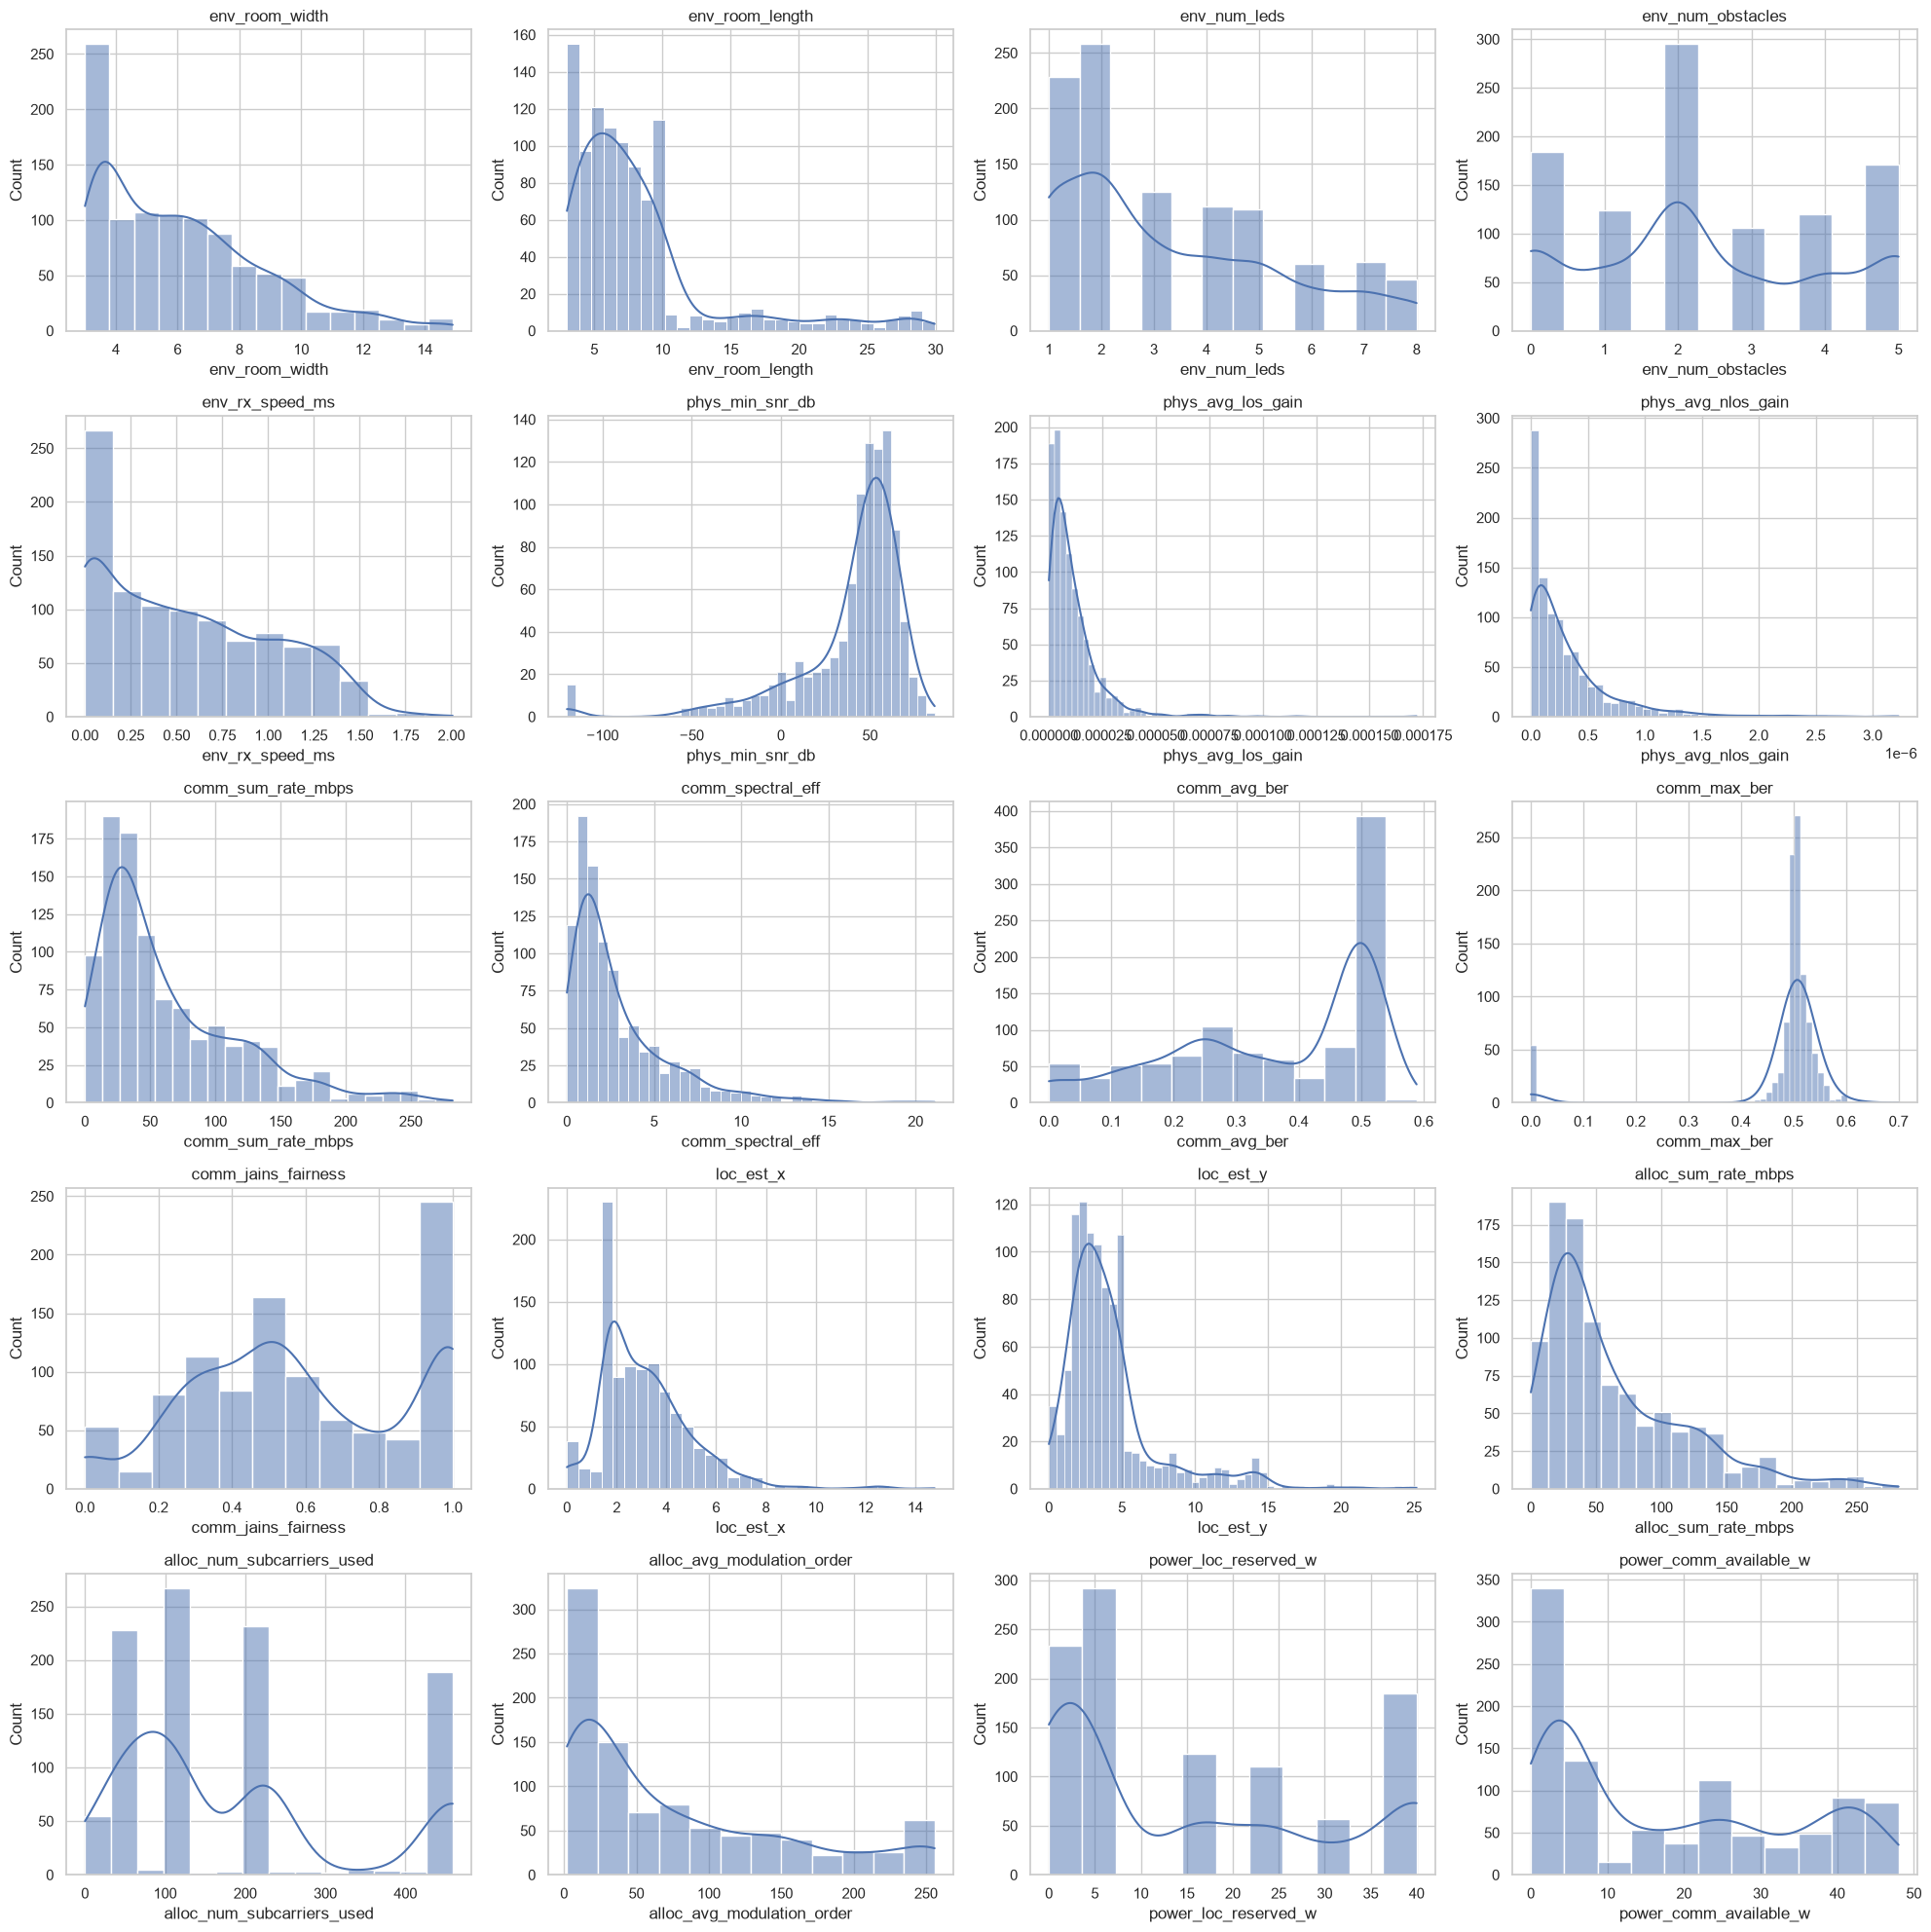

In [49]:
sample_cols = num_cols[:20]
fig, axes = plt.subplots((len(sample_cols) + 3) // 4, 4, figsize=(20, 4 * ((len(sample_cols) + 3) // 4)))
axes = axes.flatten()
for i, c in enumerate(sample_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=axes[i])
    axes[i].set_title(c)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

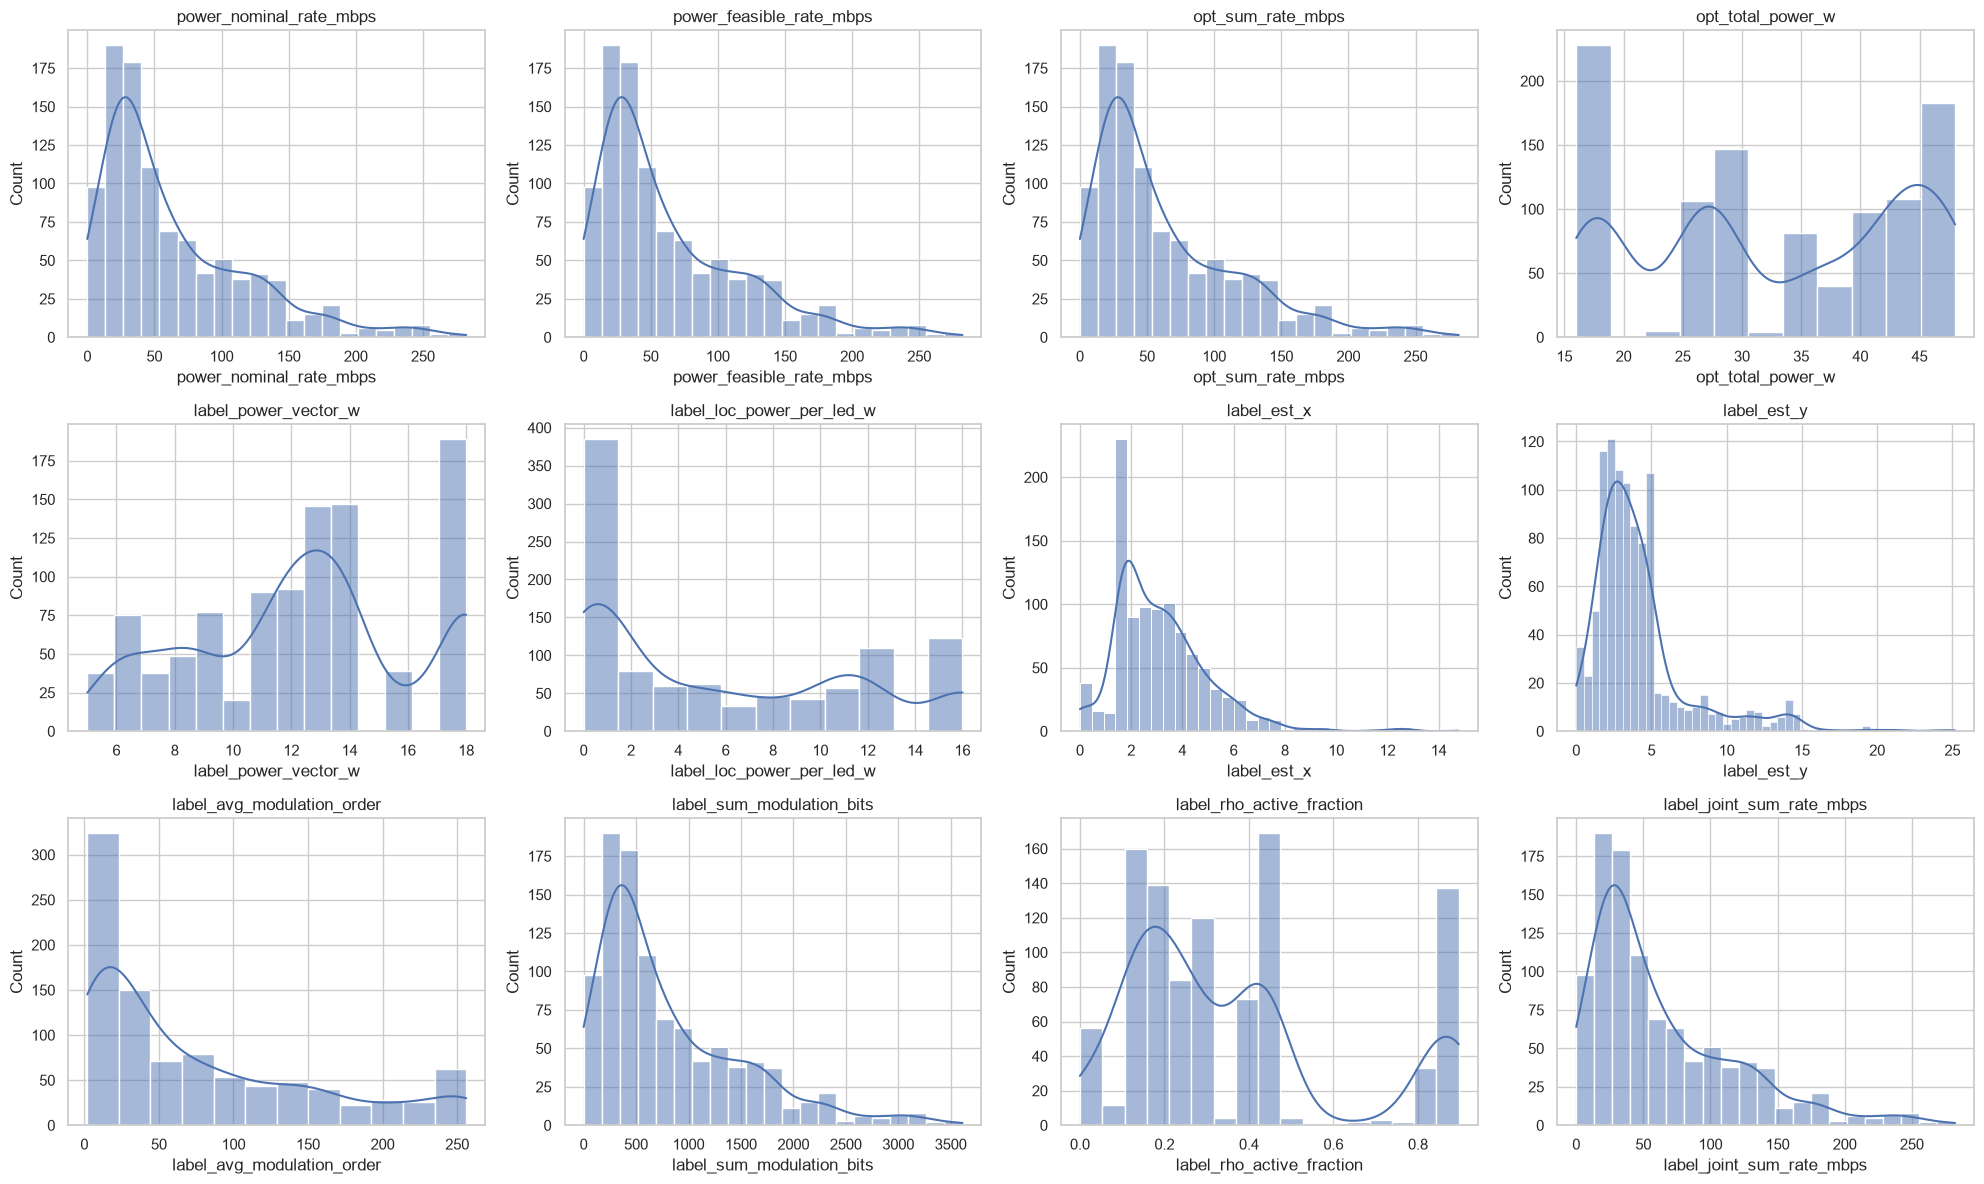

In [50]:
sample_cols2 = num_cols[20:40]
fig, axes = plt.subplots((len(sample_cols2) + 3) // 4, 4, figsize=(20, 4 * ((len(sample_cols2) + 3) // 4)))
axes = axes.flatten()
for i, c in enumerate(sample_cols2):
    sns.histplot(df[c].dropna(), kde=True, ax=axes[i])
    axes[i].set_title(c)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

## 8. Outlier Detection (IQR & Boxplots)

In [51]:
def iqr_outlier_pct(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lower) | (s > upper)).mean() * 100

outlier_pct = pd.Series({c: iqr_outlier_pct(df[c].dropna()) for c in num_cols}).sort_values(ascending=False)
outlier_pct.head(20)

label_rho_active_fraction    13.7
comm_max_ber                 11.8
env_room_length               9.5
phys_min_snr_db               9.2
label_est_y                   8.7
loc_est_y                     8.7
phys_avg_nlos_gain            7.0
comm_spectral_eff             6.0
phys_avg_los_gain             5.4
power_nominal_rate_mbps       3.2
alloc_sum_rate_mbps           3.2
label_joint_sum_rate_mbps     3.2
opt_sum_rate_mbps             3.2
power_feasible_rate_mbps      3.2
label_sum_modulation_bits     3.2
comm_sum_rate_mbps            3.2
loc_est_x                     2.1
label_est_x                   2.1
env_room_width                1.5
comm_jains_fairness           0.0
dtype: float64

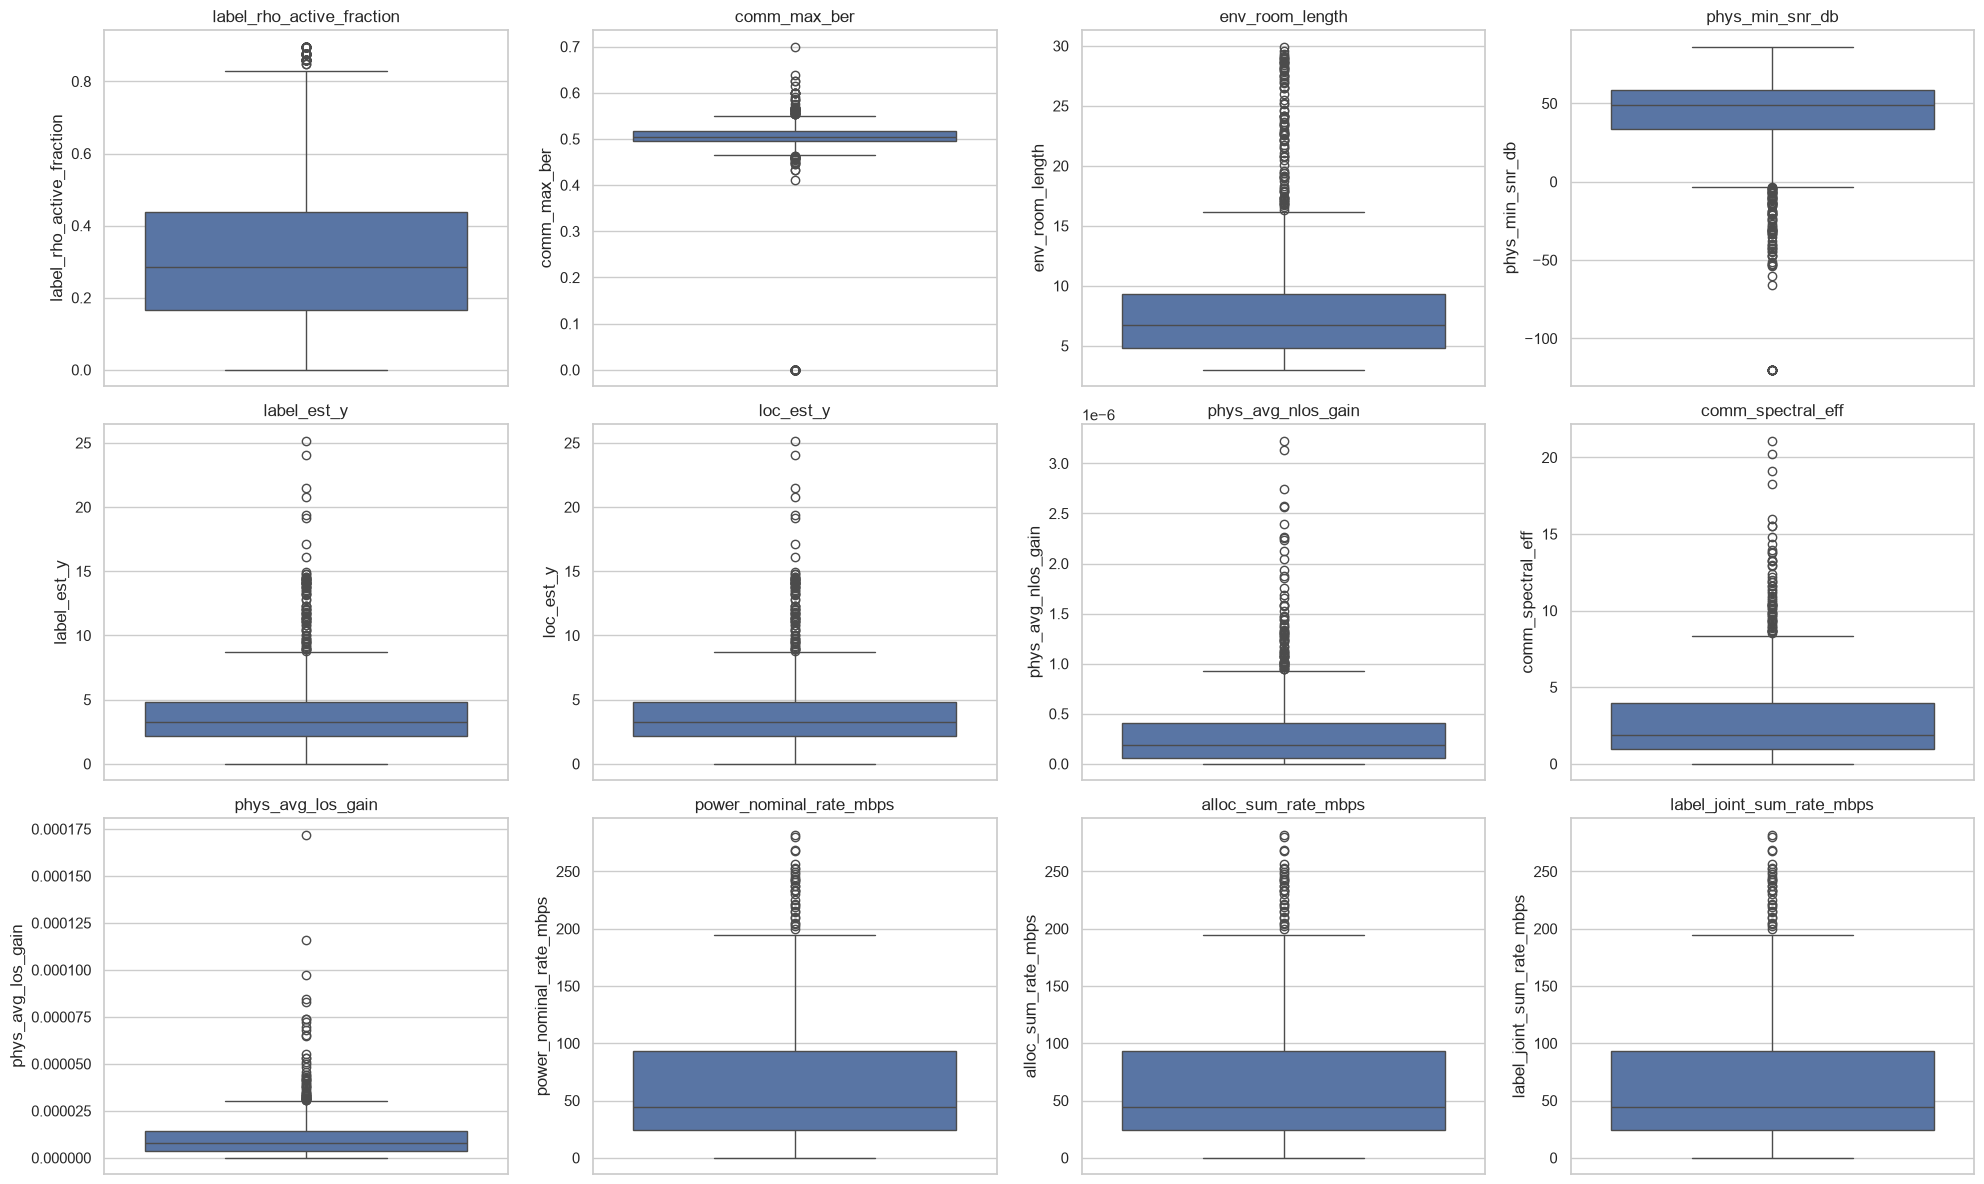

In [52]:
top_outlier_cols = outlier_pct.head(12).index.tolist()
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()
for i, c in enumerate(top_outlier_cols):
    sns.boxplot(y=df[c], ax=axes[i])
    axes[i].set_title(c)
plt.tight_layout()
plt.show()

## 9. Correlation Analysis

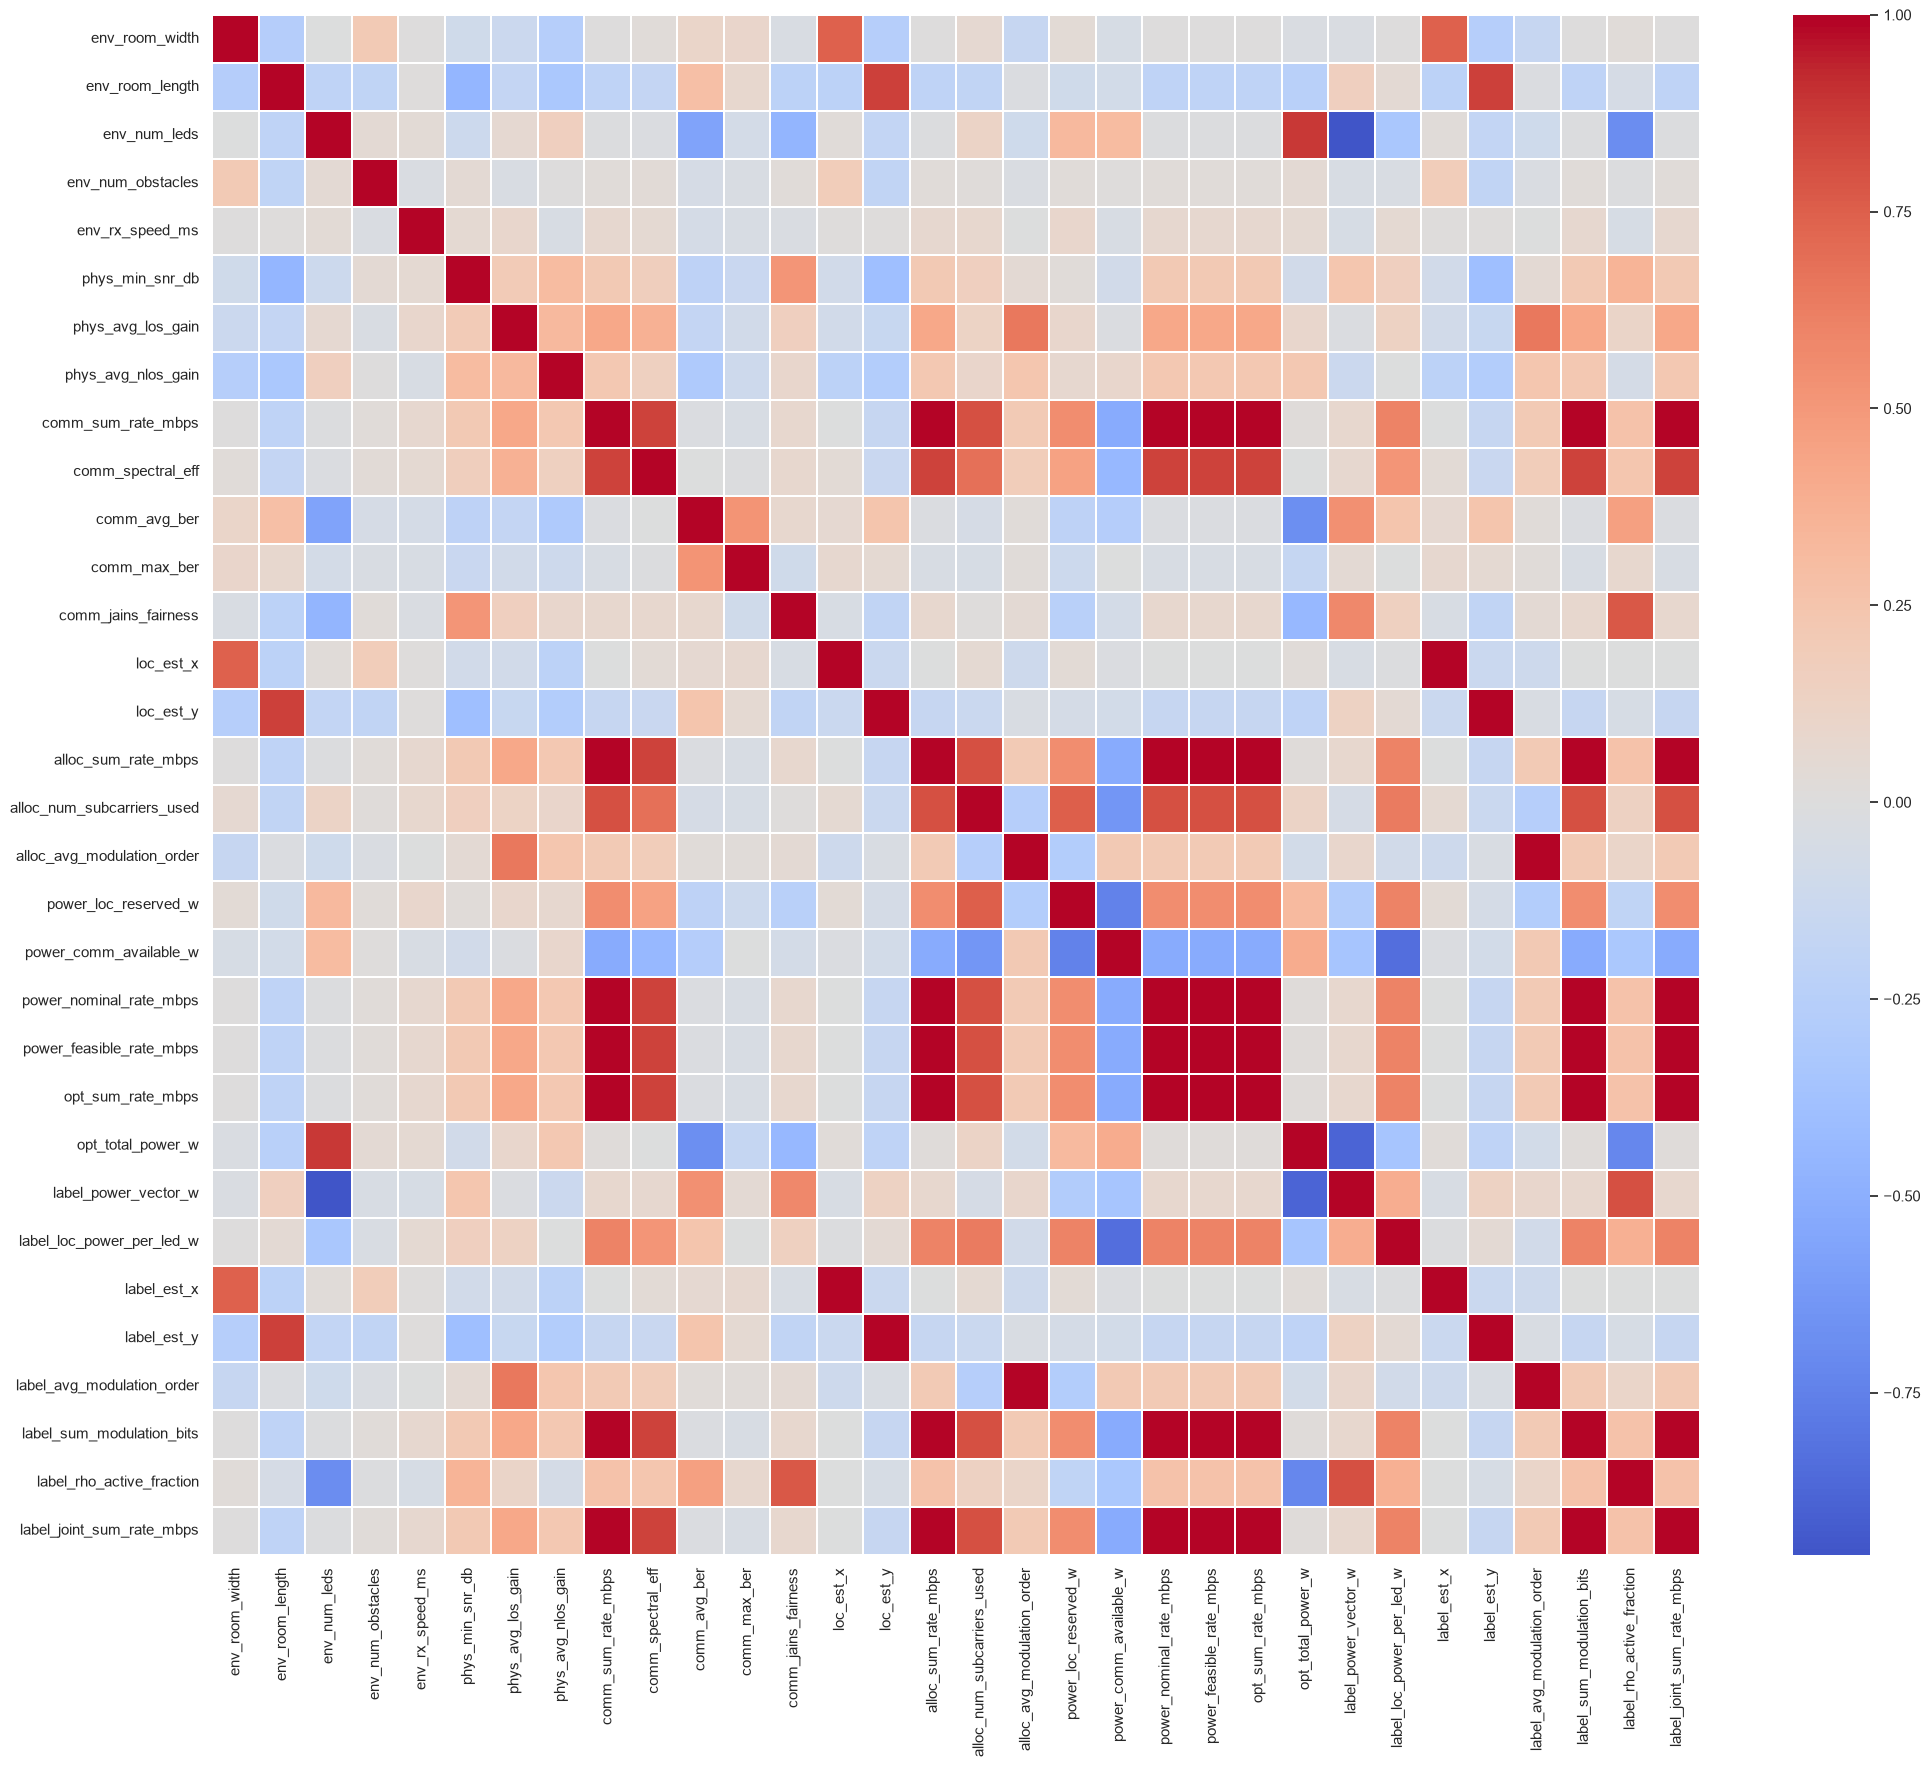

In [53]:
corr = df[num_cols].corr()
plt.figure(figsize=(24, 20))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.show()

In [54]:
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top_corr = corr_pairs.abs().sort_values(ascending=False).head(30)
top_corr_full = corr_pairs.loc[top_corr.index]
top_corr_full

opt_sum_rate_mbps           label_joint_sum_rate_mbps     1.000000
power_feasible_rate_mbps    label_joint_sum_rate_mbps     1.000000
power_nominal_rate_mbps     opt_sum_rate_mbps             1.000000
                            label_joint_sum_rate_mbps     1.000000
power_feasible_rate_mbps    opt_sum_rate_mbps             1.000000
power_nominal_rate_mbps     power_feasible_rate_mbps      1.000000
alloc_sum_rate_mbps         opt_sum_rate_mbps             1.000000
                            label_joint_sum_rate_mbps     1.000000
alloc_avg_modulation_order  label_avg_modulation_order    1.000000
alloc_sum_rate_mbps         power_nominal_rate_mbps       1.000000
loc_est_y                   label_est_y                   1.000000
loc_est_x                   label_est_x                   1.000000
comm_sum_rate_mbps          label_joint_sum_rate_mbps     1.000000
                            power_feasible_rate_mbps      1.000000
                            power_nominal_rate_mbps       1.00

## 10. Group-wise Analysis

In [55]:
group_col = "meta_scenario_type"
key_metrics = ["comm_sum_rate_mbps", "phys_avg_snr_db", "loc_error_3d_m", "label_joint_sum_rate_mbps", "opt_total_power_w"]
key_metrics = [c for c in key_metrics if c in df.columns]
df.groupby(group_col)[key_metrics].agg(["mean", "median", "std"])

comm_sum_rate_mbps                       phys_avg_snr_db  \
                                 mean     median        std            mean   
meta_scenario_type                                                            
corridor                    47.478516  32.187500  49.722146       31.554835   
lab                         63.198426  45.312500  50.788402       57.000594   
lobby                       59.750744  43.359375  49.465481       48.252514   
meeting_room                74.837187  54.843750  60.859522       60.168891   
open_office                 65.481771  46.562500  57.124910       51.734883   

                                         loc_error_3d_m                      \
                       median        std           mean    median       std   
meta_scenario_type                                                            
corridor            41.294732  32.891773       4.920758  3.867254  4.009336   
lab                 58.866178  13.032647       1.551458  1.211338  1.516964   
lobby               54.309392  20.781558       2.059554  1.383701  1.950916   
meeting_room        61.855780  10.276328       1.213375  0.984337  1.089216   
open_office         56.089623  17.989526       2.129073  1.528718  2.158785   

                   label_joint_sum_rate_mbps                        \
                                        mean     median        std   
meta_scenario_type                                                   
corridor                           47.478516  32.187500  49.722146   
lab                                63.198426  45.312500  50.788402   
lobby                              59.750744  43.359375  49.465481   
meeting_room                       74.837187  54.843750  60.859522   
open_office                        65.481771  46.562500  57.124910   

                   opt_total_power_w                    
                                mean median        std  
meta_scenario_type                                      
corridor                   27.800000   26.0  10.830193  
lab                        33.503759   36.0  10.850354  
lobby                      34.761905   34.0   8.274712  
meeting_room               34.992000   38.0  10.890102  
open_office                32.737374   28.0  11.875912

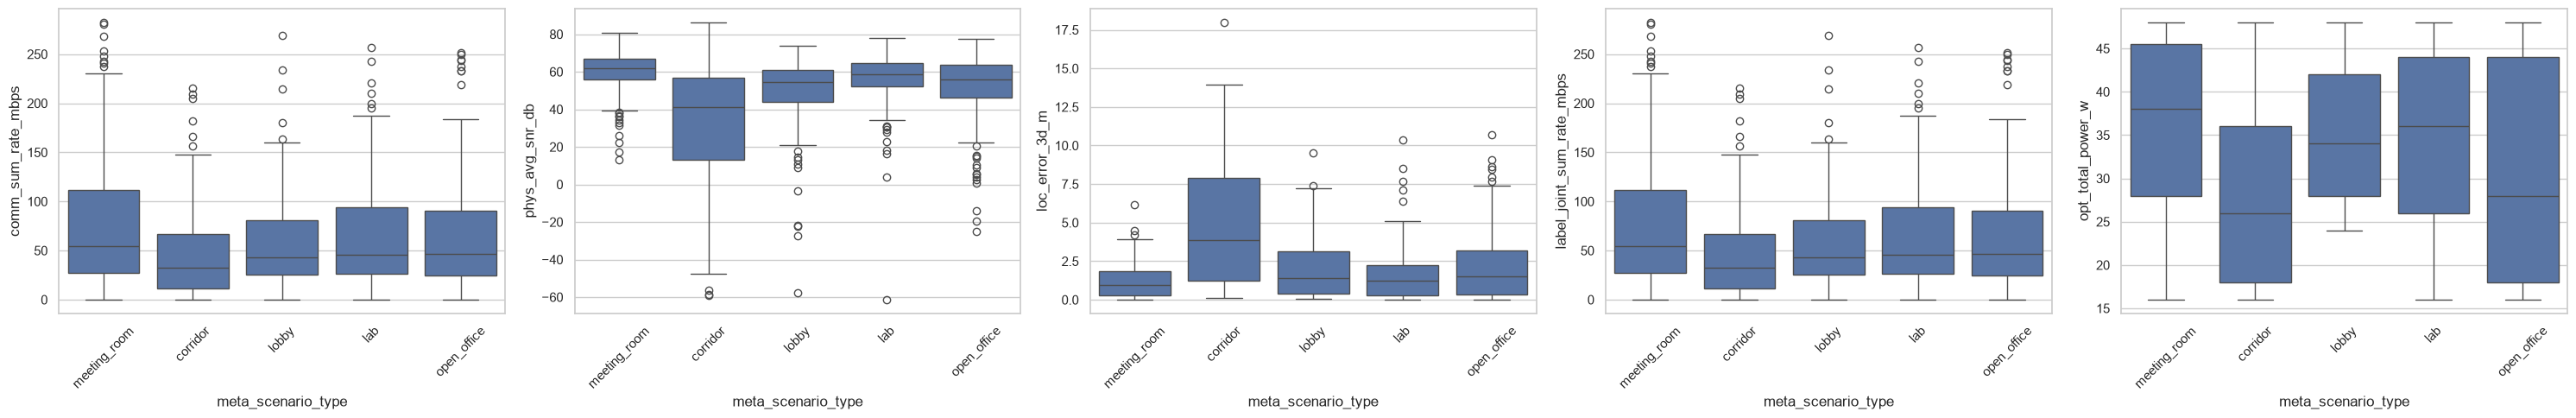

In [56]:
fig, axes = plt.subplots(1, len(key_metrics), figsize=(6 * len(key_metrics), 5))
for ax, c in zip(axes, key_metrics):
    sns.boxplot(data=df, x=group_col, y=c, ax=ax)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [57]:
pipeline_col = "meta_pipeline_mode"
df.groupby(pipeline_col)[key_metrics].mean()

,comm_sum_rate_mbps,phys_avg_snr_db,loc_error_3d_m,label_joint_sum_rate_mbps,opt_total_power_w
meta_pipeline_mode,,,,,
optimize,63.610625,51.576478,2.184413,63.610625,32.97


In [59]:
!pip install -U nbformat

  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached rpds_py-2026.6.3-cp314-cp314-win_amd64.whl.metadata (4.2 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)
Using cached rpds_py-2026.6.3-cp314-cp314-win_amd64.whl (220 kB)

   ----------- ---------------------------- 2/7 [attrs]
   ----------- ---------------------------- 2/7 [attrs]
   ---------------------- ----------------- 4/7 [jsonschema-specifications]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   -----------------------

## 11. Feasibility / Status Flags

In [61]:
flag_cols = ["opt_converged", "opt_feasible", "label_qos_feasible", "label_joint_converged", "label_joint_feasible", "meta_is_valid"]
flag_cols = [c for c in flag_cols if c in df.columns]
df[flag_cols].mean()

opt_converged            0.000
opt_feasible             0.000
label_qos_feasible       0.402
label_joint_converged    0.000
label_joint_feasible     0.000
meta_is_valid            1.000
dtype: float64

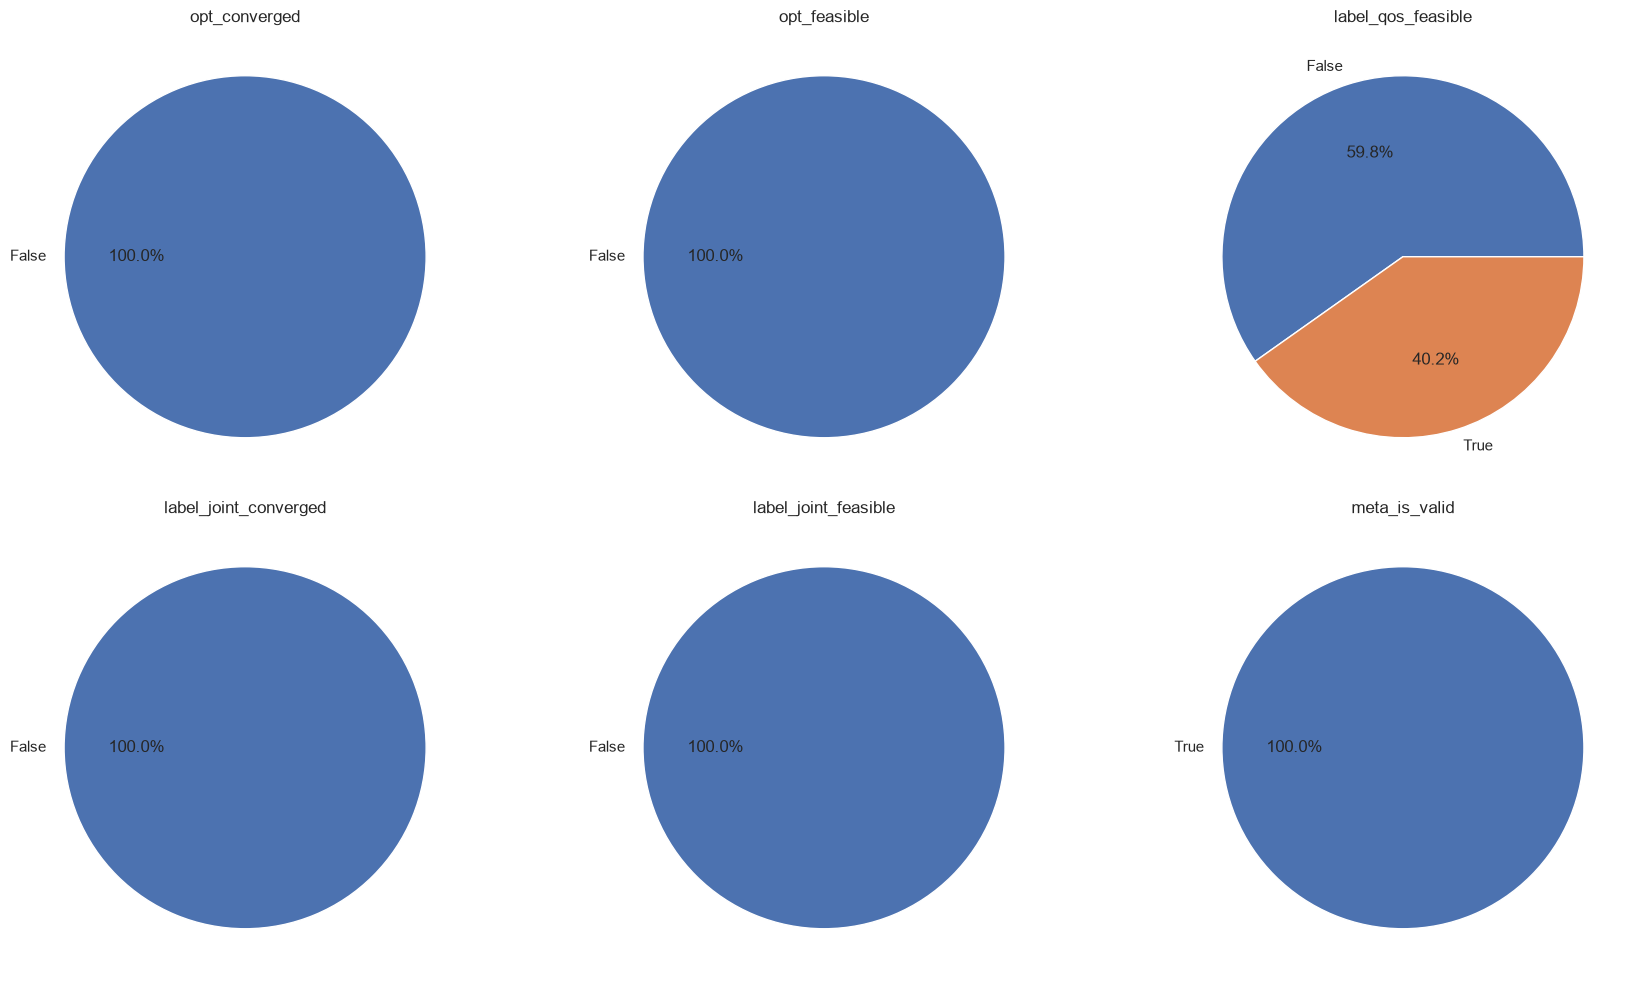

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, c in enumerate(flag_cols):
    df[c].value_counts().plot.pie(autopct="%1.1f%%", ax=axes[i])
    axes[i].set_title(c)
    axes[i].set_ylabel("")
plt.tight_layout()
plt.show()

In [63]:
pd.crosstab(df["loc_status"], df["alloc_qos_status"])

alloc_qos_status,FEASIBLE,INFEASIBLE_QOS
loc_status,,
INSUFFICIENT_GEOMETRY,288,214
LOW_CONFIDENCE,82,298
SOLVER_FAILED,32,86


## 12. Relationship Between Key Continuous Variables

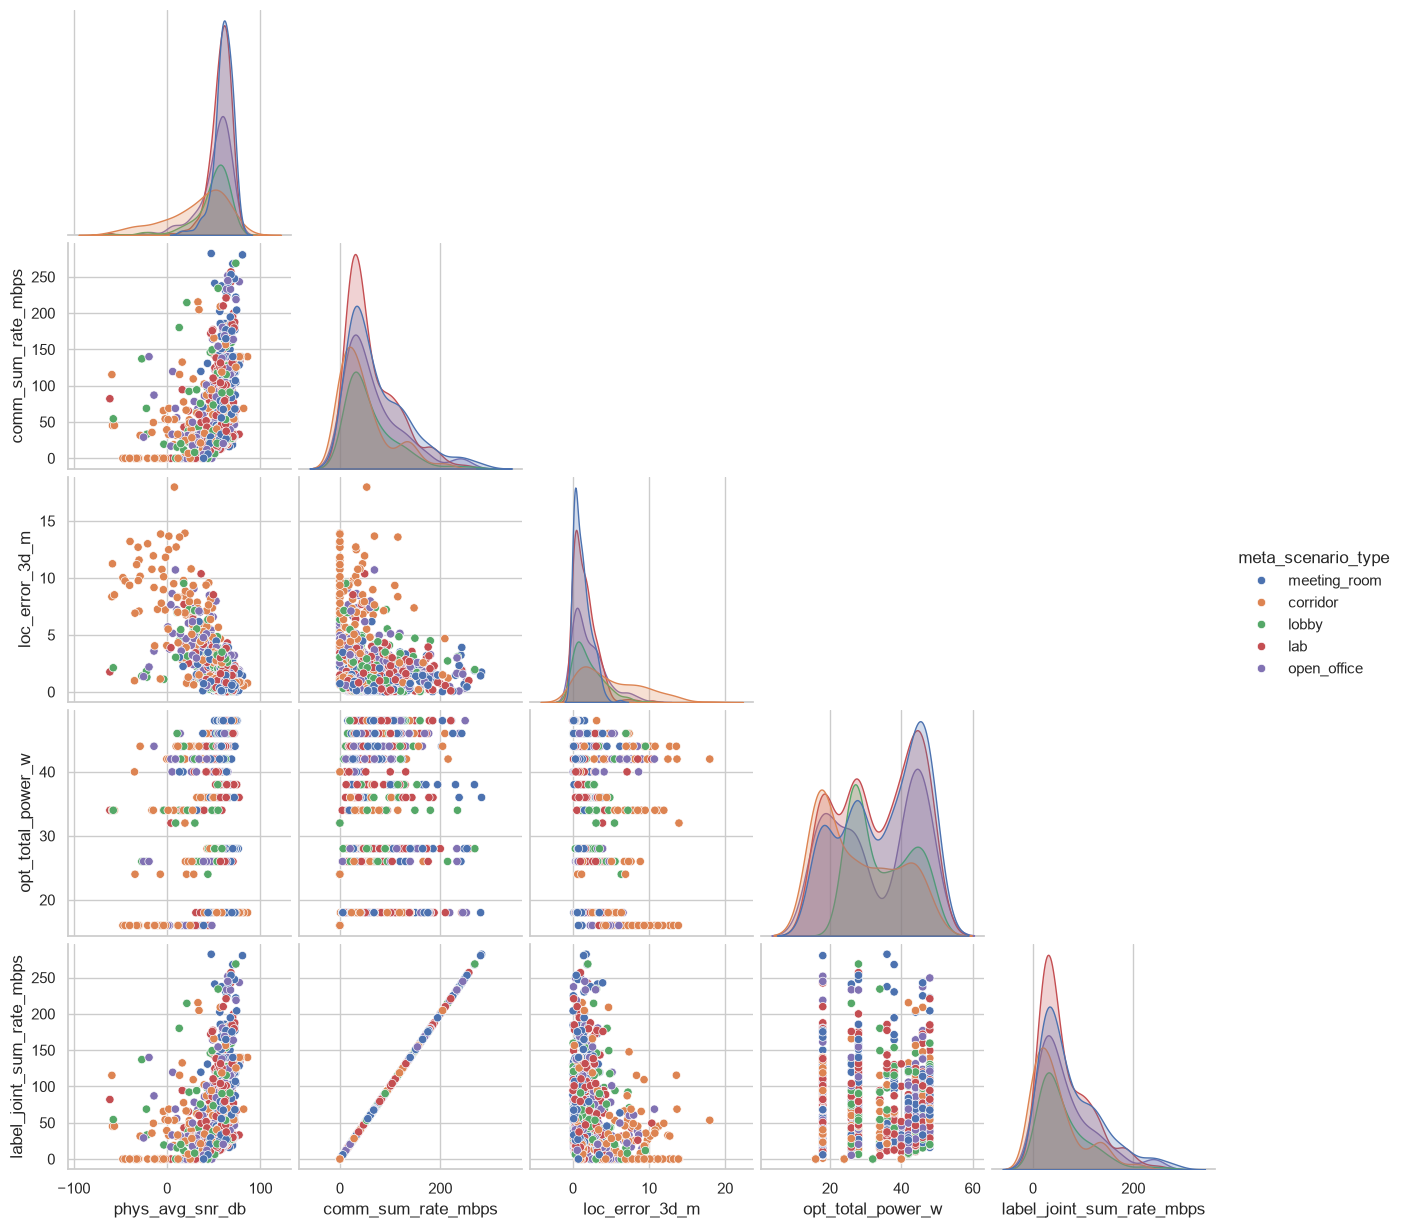

In [64]:
pair_cols = ["phys_avg_snr_db", "comm_sum_rate_mbps", "loc_error_3d_m", "opt_total_power_w", "label_joint_sum_rate_mbps"]
pair_cols = [c for c in pair_cols if c in df.columns]
sns.pairplot(df[pair_cols + [group_col]].dropna(), hue=group_col, corner=True)
plt.show()

In [72]:
!pip install nbformat==4.2.0


  Attempting uninstall: nbformat

    Found existing installation: nbformat 5.10.4

    Uninstalling nbformat-5.10.4:

   -------------------- ------------------- 1/2 [nbformat]
      Successfully uninstalled nbformat-5.10.4
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   ---------------------------------------- 2/2 [nbformat]



In [ ]:
import plotly.io as pio

fig = px.scatter_3d(
    df.dropna(subset=["loc_est_x","loc_est_y","loc_est_z"]),
    x="loc_est_x",
    y="loc_est_y",
    z="loc_est_z",
    color=group_col,
    opacity=0.6,
)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

## 13. Dimensionality Reduction

In [67]:
X = df[num_cols].fillna(df[num_cols].median())
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.31770093, 0.1533134 ])

In [68]:
plot_df = pd.DataFrame(pcs, columns=["PC1", "PC2"])
plot_df[group_col] = df[group_col].values
fig = px.scatter(plot_df, x="PC1", y="PC2", color=group_col, opacity=0.7)
fig.show()

In [69]:
loadings = pd.DataFrame(pca.components_.T, index=num_cols, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(15)

,PC1,PC2
comm_sum_rate_mbps,0.308360,0.016755
label_joint_sum_rate_mbps,0.308360,0.016755
power_feasible_rate_mbps,0.308360,0.016755
alloc_sum_rate_mbps,0.308360,0.016755
opt_sum_rate_mbps,0.308360,0.016755
power_nominal_rate_mbps,0.308360,0.016755
label_sum_modulation_bits,0.308360,0.016755
comm_spectral_eff,0.269424,0.008435
alloc_num_subcarriers_used,0.260131,0.054030
label_loc_power_per_led_w,0.214873,-0.166053


In [70]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca")
tsne_res = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(tsne_res, columns=["TSNE1", "TSNE2"])
tsne_df[group_col] = df[group_col].values
fig = px.scatter(tsne_df, x="TSNE1", y="TSNE2", color=group_col, opacity=0.7)
fig.show()

## 14. Multivariate Outlier Detection

In [ ]:
iso = IsolationForest(contamination=0.03, random_state=42)
outlier_pred = iso.fit_predict(X_scaled)
df["is_outlier"] = outlier_pred == -1
df["is_outlier"].value_counts()

In [ ]:
plot_df["is_outlier"] = df["is_outlier"].values
fig = px.scatter(plot_df, x="PC1", y="PC2", color="is_outlier", opacity=0.7)
fig.show()

## 15. Feature Relationships With a Target Metric

In [ ]:
target = "label_joint_sum_rate_mbps"
target_corr = df[num_cols].corr()[target].drop(target).sort_values(key=abs, ascending=False)
target_corr.head(20)

In [ ]:
top_feats = target_corr.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, c in enumerate(top_feats):
    sns.regplot(data=df, x=c, y=target, scatter_kws={"alpha": 0.4}, ax=axes[i])
    axes[i].set_title(f"{c} vs {target}")
plt.tight_layout()
plt.show()

## 16. Time-based View

In [ ]:
df["meta_timestamp"] = pd.to_datetime(df["meta_timestamp"])
df.set_index("meta_timestamp")[key_metrics].resample("1min").mean().plot(subplots=True, figsize=(14, 12))
plt.tight_layout()
plt.show()

## 17. Summary Report

In [ ]:
summary = {
    "n_rows": len(df),
    "n_cols": df.shape[1],
    "n_numeric": len(num_cols),
    "n_categorical": len(cat_cols),
    "n_constant_cols": len(constant_cols),
    "n_duplicate_rows": int(df.duplicated().sum()),
    "pct_multivariate_outliers": float(df["is_outlier"].mean() * 100),
    "n_scenario_types": df[group_col].nunique(),
}
pd.Series(summary)